# Prédiction de la pollution de l'air à partir de capteurs à bas coût

**Auteur :** Issa Marc Badji — Sorbonne Université (M1 Mathématiques et applications, cours *Bases de l'apprentissage statistique*)

## Objectif

Un dispositif de capteurs chimiques bon marché (oxydes métalliques), installé au bord d'une route dans une ville italienne, enregistre des réponses horaires entre mars 2004 et février 2005. Un analyseur de référence certifié mesure en parallèle les vraies concentrations de polluants.

**Question :** peut-on estimer les concentrations réelles de quatre polluants — CO, benzène (C6H6), NOx et NO2 — à partir des seules réponses des capteurs et des conditions météorologiques ? C'est un problème de **régression multi-sorties** (4 cibles).

## Ce que contient ce notebook

Toutes les méthodes sont **implémentées à la main avec NumPy** (pas de `scikit-learn` pour l'apprentissage) :

| Méthode | Implémentation |
|---|---|
| Moindres carrés et Ridge | forme fermée, intercept non pénalisé |
| Ridge à noyau gaussien | noyau vectorisé, résolution par Cholesky |
| Réseau de neurones dense | rétropropagation + optimiseur Adam + arrêt précoce |

L'implémentation est **vérifiée** : comparaison avec `scikit-learn` pour Ridge et Ridge à noyau, et vérification numérique du gradient (différences finies) pour le réseau de neurones.

**Protocole :** découpage **chronologique** train / validation / test (60 / 20 / 20 %), standardisation apprise sur le train uniquement, choix des hyperparamètres sur la validation, évaluation finale une seule fois sur le test.

**Données :** [UCI Air Quality](https://archive.ics.uci.edu/dataset/360/air+quality) (De Vito et al., 2008), fichier `AirQualityUCI.csv` à placer à côté du notebook.

## 0. Configuration

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import cho_factor, cho_solve

SEED = 0
DATA_PATH = "AirQualityUCI.csv"

TARGETS = ["CO(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)"]
SENSORS = ["PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S3(NOx)", "PT08.S4(NO2)", "PT08.S5(O3)"]
WEATHER = ["T", "RH", "AH"]  # température, humidité relative, humidité absolue

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

## 1. Chargement et nettoyage

Particularités du fichier : séparateur `;`, virgule décimale, deux colonnes vides en fin de ligne, lignes vides en fin de fichier, et **valeurs manquantes codées par `-200`**.

In [2]:
def load_air_quality(path):
    # Charge le fichier UCI et renvoie un DataFrame indexé par la date et l'heure.
    df = pd.read_csv(path, sep=";", decimal=",")
    df = df.dropna(axis=1, how="all").dropna(axis=0, how="all")
    df["Datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"], format="%d/%m/%Y %H.%M.%S")
    df = df.drop(columns=["Date", "Time"]).set_index("Datetime").sort_index()
    return df.replace(-200, np.nan)


df_raw = load_air_quality(DATA_PATH)
print(f"{df_raw.shape[0]} mesures horaires, du {df_raw.index.min():%d/%m/%Y} au {df_raw.index.max():%d/%m/%Y}")
df_raw.head()

9357 mesures horaires, du 10/03/2004 au 04/04/2005


,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
Datetime,,,,,,,,,,,,,
2004-03-10 18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
2004-03-10 19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2004-03-10 20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
2004-03-10 21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
2004-03-10 22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


## 2. Analyse exploratoire

### 2.1 Valeurs manquantes

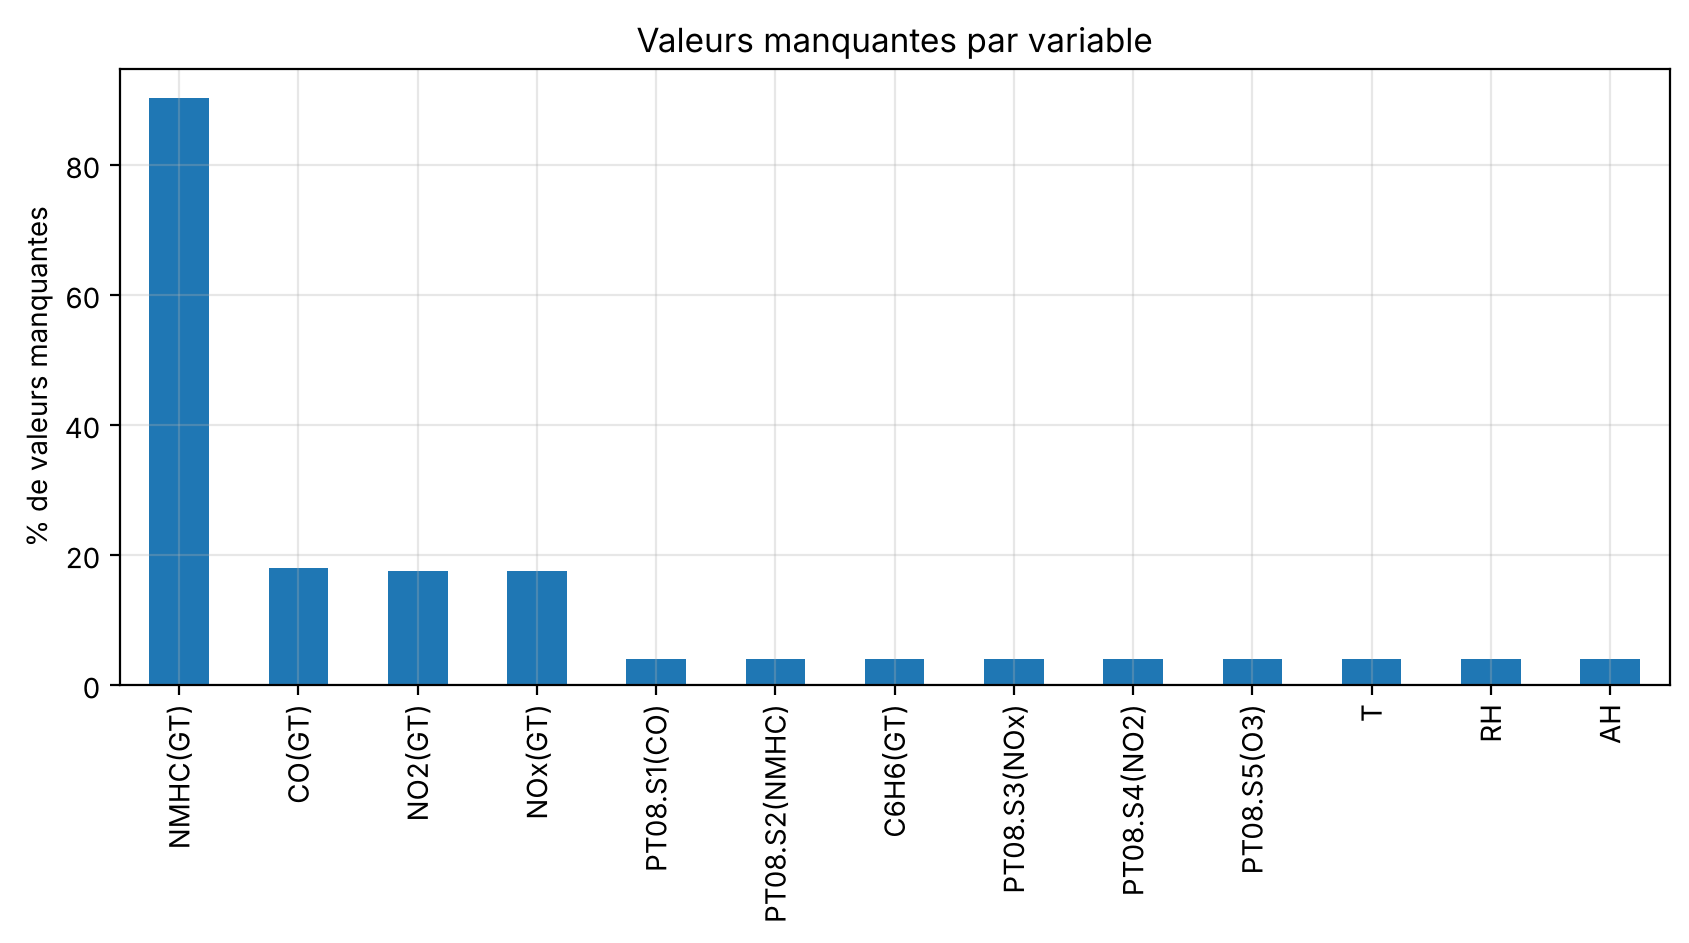

,NMHC(GT),CO(GT),NO2(GT),NOx(GT),PT08.S1(CO),PT08.S2(NMHC),C6H6(GT),PT08.S3(NOx),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
% manquant,90.2,18.0,17.5,17.5,3.9,3.9,3.9,3.9,3.9,3.9,3.9,3.9,3.9


In [3]:
missing_pct = 100 * df_raw.isna().mean().sort_values(ascending=False)

ax = missing_pct.plot.bar(color="tab:blue")
ax.set_ylabel("% de valeurs manquantes")
ax.set_title("Valeurs manquantes par variable")
plt.show()

missing_pct.round(1).to_frame("% manquant").T

`NMHC(GT)` est manquante dans la grande majorité des cas : on l'**exclut**. C'est aussi une mesure de l'analyseur de référence, qui ne serait pas disponible en conditions réelles (on veut justement s'en passer). Les capteurs et la météo ont des pannes simultanées (mêmes lignes manquantes) ; les cibles ont chacune leurs propres trous.

Les modèles utilisés ici ne gèrent pas les valeurs manquantes : on garde les heures où **toutes** les variables utiles sont observées.

### 2.2 Distribution et dynamique des cibles

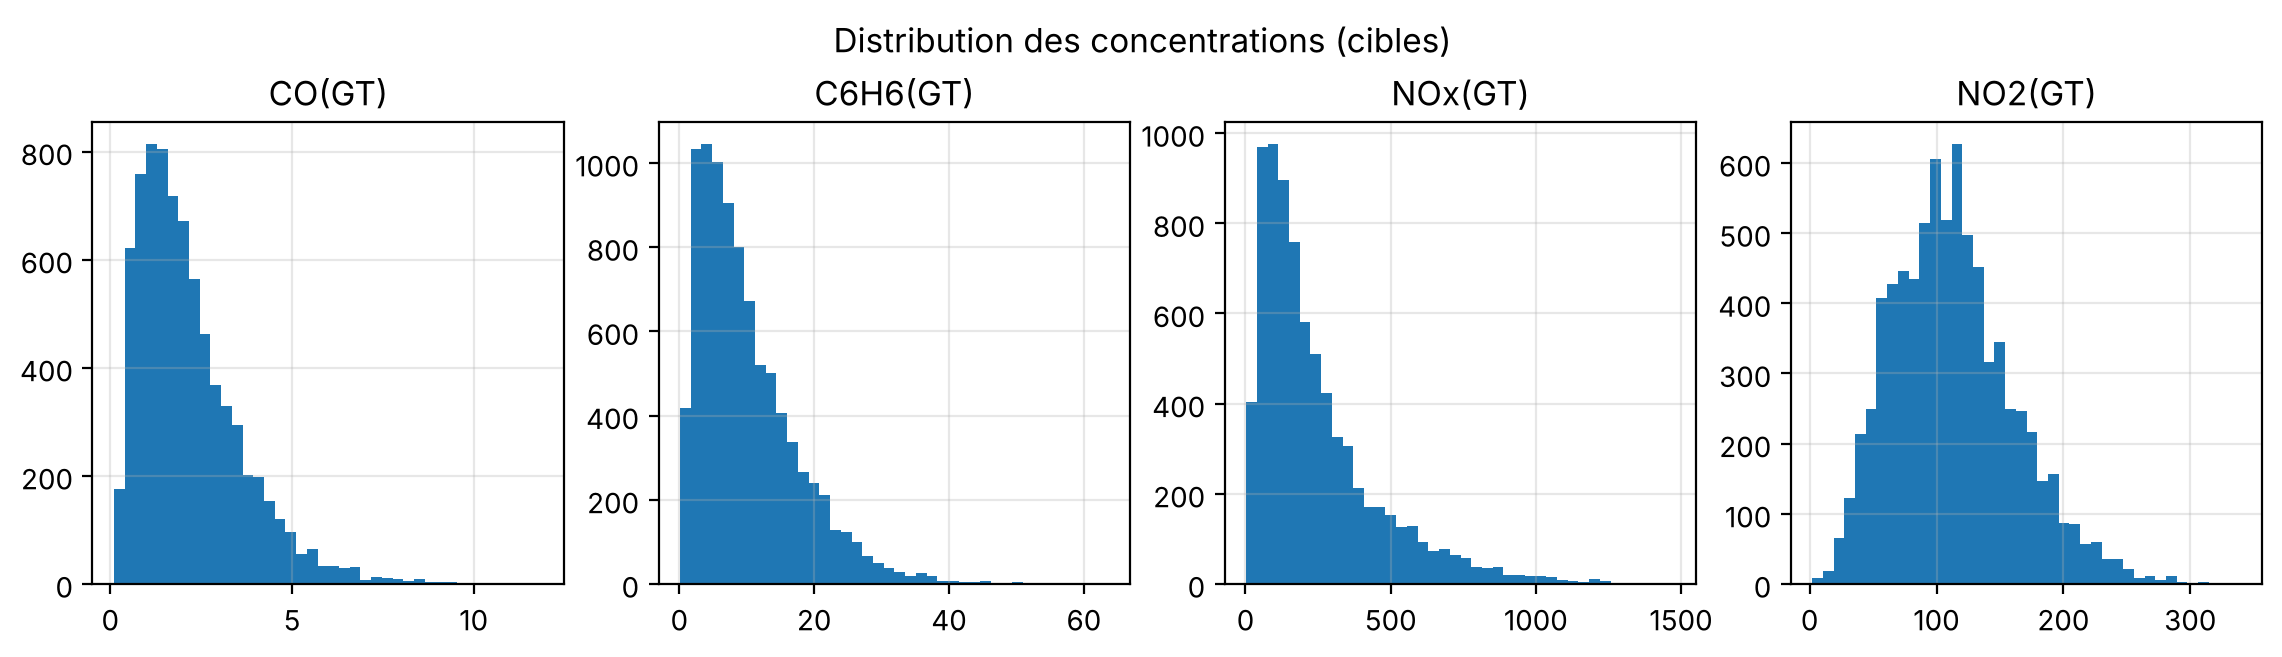

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, target in zip(axes, TARGETS):
    ax.hist(df_raw[target].dropna(), bins=40, color="tab:blue")
    ax.set_title(target)
fig.suptitle("Distribution des concentrations (cibles)", y=1.05)
plt.show()

Les distributions sont asymétriques à droite (pics de pollution ponctuels).

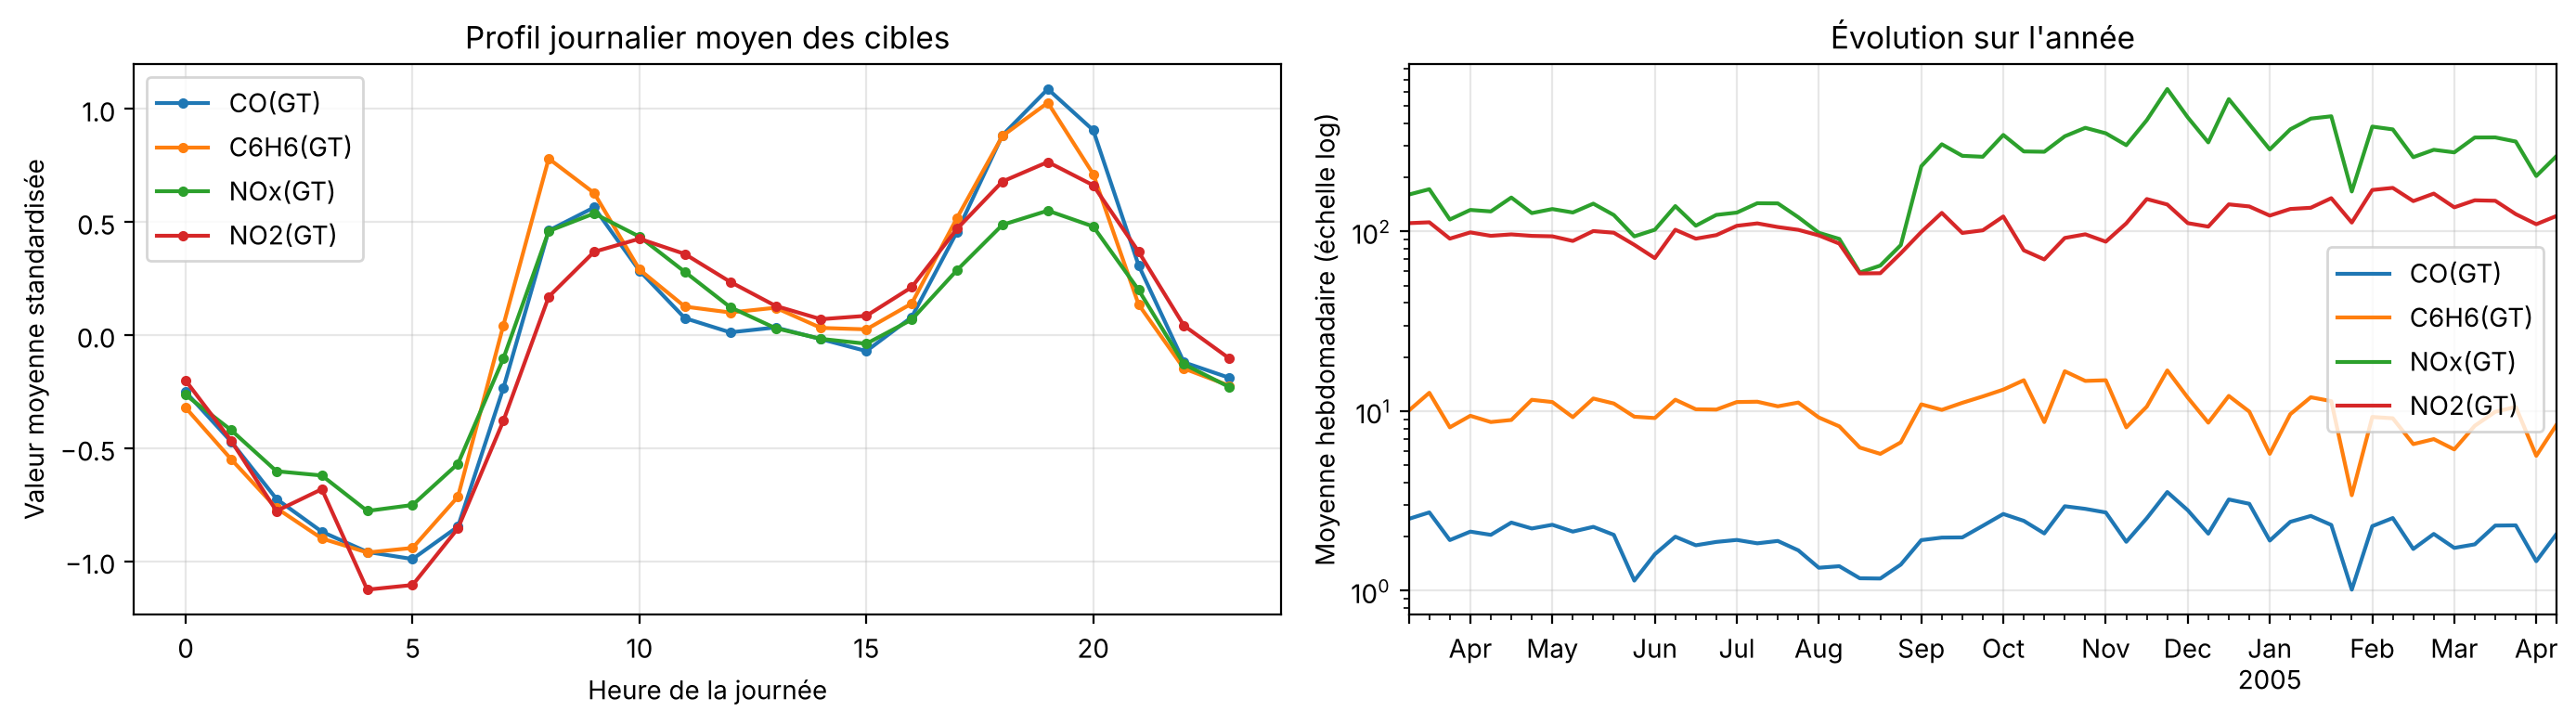

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Profil journalier moyen (cibles standardisées pour les comparer sur une même échelle)
z = (df_raw[TARGETS] - df_raw[TARGETS].mean()) / df_raw[TARGETS].std()
z.groupby(z.index.hour).mean().plot(ax=axes[0], marker="o", ms=3)
axes[0].set(xlabel="Heure de la journée", ylabel="Valeur moyenne standardisée",
            title="Profil journalier moyen des cibles")

# Évolution sur l'année (moyenne hebdomadaire)
df_raw[TARGETS].resample("W").mean().plot(ax=axes[1], logy=True)
axes[1].set(xlabel="", ylabel="Moyenne hebdomadaire (échelle log)", title="Évolution sur l'année")
plt.tight_layout()
plt.show()

Deux pics quotidiens (vers 8 h et 19 h) qui correspondent au trafic routier : l'**heure de la journée** est une variable utile. Sur l'année, les niveaux évoluent nettement : NOx est multiplié par plus de deux à partir de septembre (saut brutal, pas une évolution progressive) et NO2 augmente en hiver. Cela annonce un **décalage de distribution** entre le début et la fin de l'enregistrement.

### 2.3 Corrélations

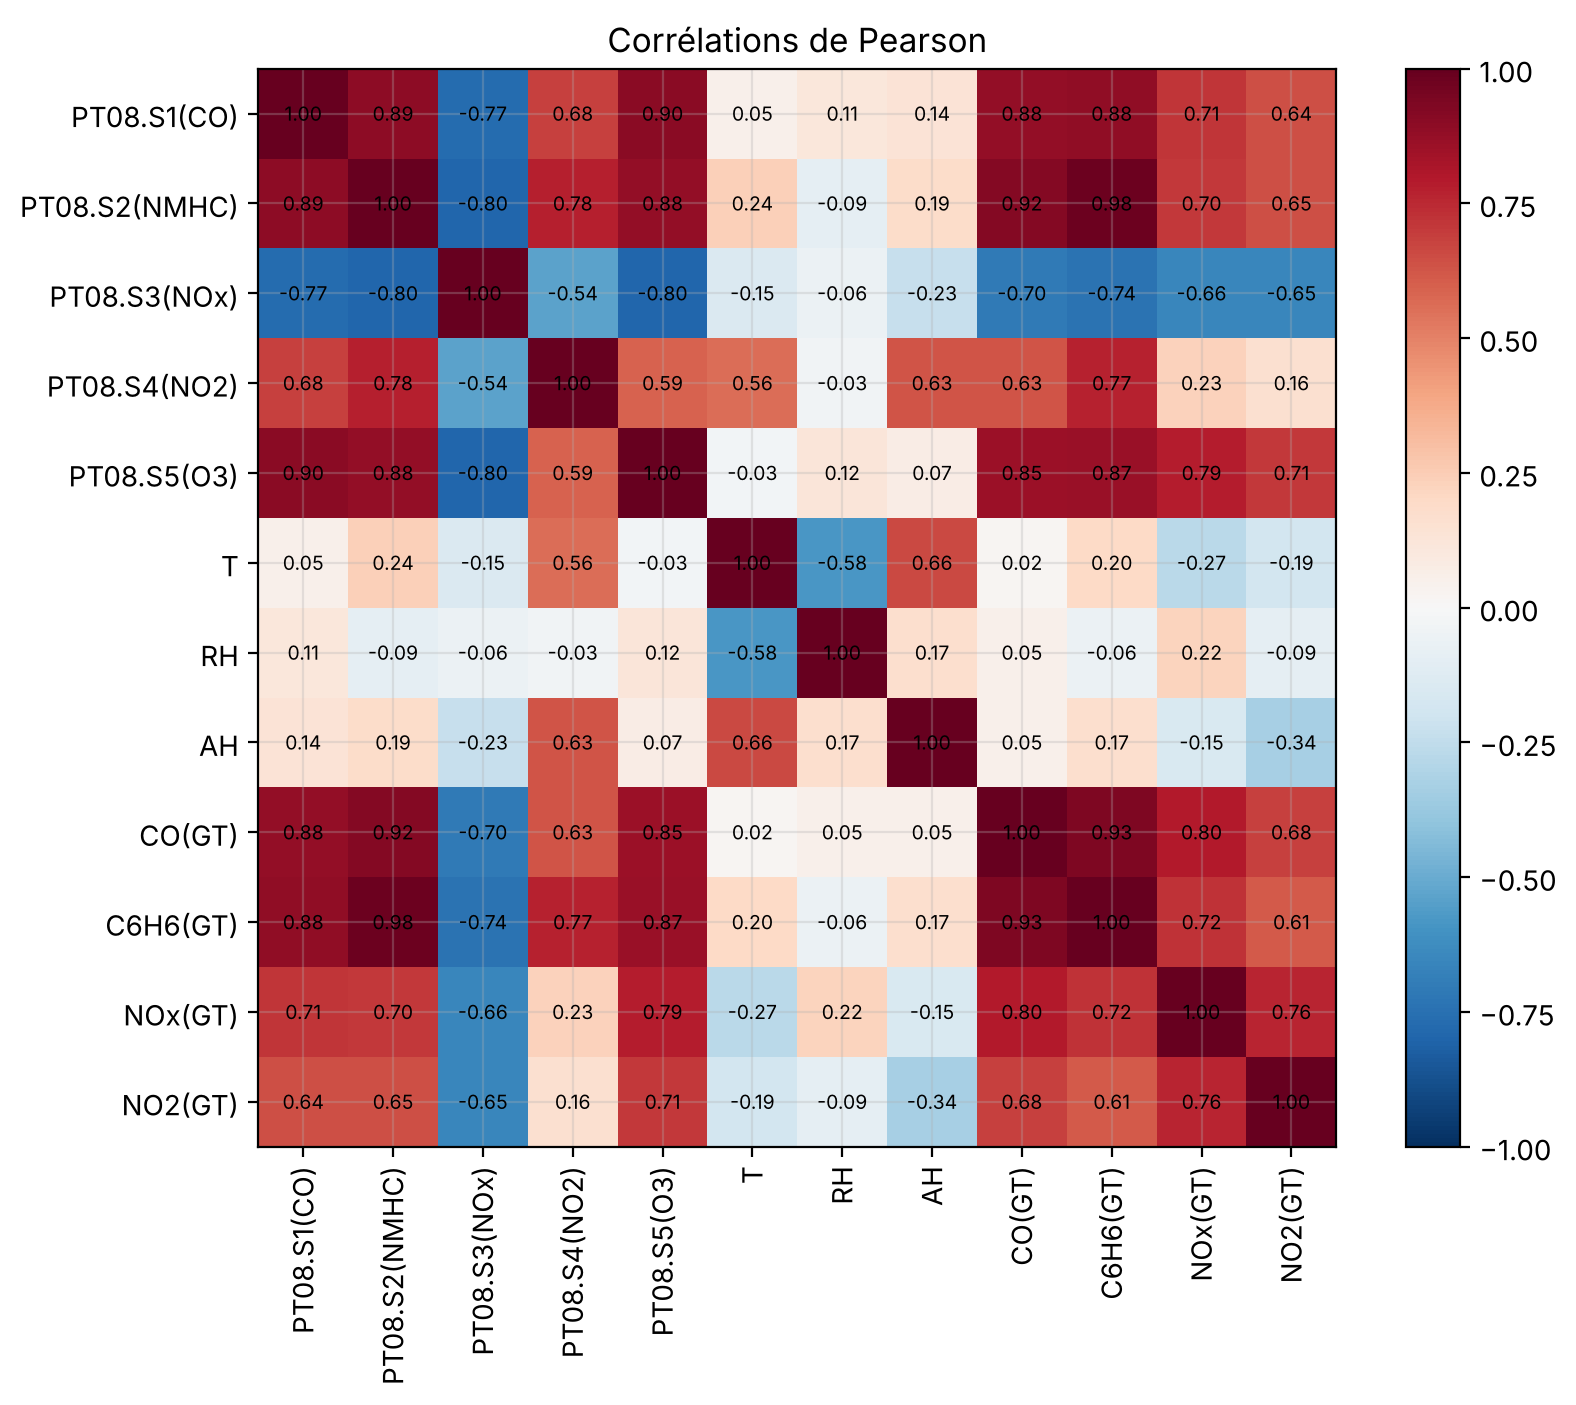

In [6]:
cols = SENSORS + WEATHER + TARGETS
corr = df_raw[cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=90)
ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im)
ax.set_title("Corrélations de Pearson")
plt.show()

Les capteurs sont fortement corrélés entre eux et avec les cibles (y compris de façon négative pour `PT08.S3(NOx)`) : la prédiction est faisable, mais les variables explicatives sont **colinéaires**, ce qui justifie la régularisation (Ridge). Certaines relations capteur / cible sont visiblement non linéaires, ce qui motive les méthodes à noyau et les réseaux de neurones.

## 3. Préparation des données

**Variables explicatives :** les 5 capteurs, les 3 variables météo, et l'heure de la journée encodée de façon cyclique par $(\sin, \cos)$ (pour que 23 h et 0 h soient proches), plus un indicateur de week-end.

**Découpage chronologique :** les observations sont des séries temporelles fortement autocorrélées. Un découpage aléatoire mettrait des heures voisines à la fois dans le train et dans le test, ce qui surestimerait les performances (on le vérifie en section 6). On coupe donc dans l'ordre du temps : 60 % train, 20 % validation, 20 % test.

**Standardisation :** moyennes et écarts-types calculés **sur le train uniquement**, appliqués ensuite à la validation et au test. Les cibles sont aussi standardisées, pour que les quatre polluants (d'échelles très différentes) pèsent autant dans la perte.

In [7]:
def build_features(df):
    # Capteurs + météo + heure (encodage cyclique) + indicateur de week-end.
    X = df[SENSORS + WEATHER].copy()
    hour = df.index.hour
    X["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    X["hour_cos"] = np.cos(2 * np.pi * hour / 24)
    X["weekend"] = (df.index.dayofweek >= 5).astype(float)
    return X


data = df_raw[SENSORS + WEATHER + TARGETS].dropna()
X_all = build_features(data).to_numpy()
Y_all = data[TARGETS].to_numpy()
FEATURE_NAMES = list(build_features(data).columns)

n = len(data)
i_val, i_test = int(0.6 * n), int(0.8 * n)
X_train, X_val, X_test = X_all[:i_val], X_all[i_val:i_test], X_all[i_test:]
Y_train, Y_val, Y_test = Y_all[:i_val], Y_all[i_val:i_test], Y_all[i_test:]

print(f"Observations complètes : {n} sur {len(df_raw)}  |  {X_all.shape[1]} variables explicatives")
for name, part in [("train", slice(0, i_val)), ("validation", slice(i_val, i_test)), ("test", slice(i_test, n))]:
    idx = data.index[part]
    print(f"  {name:<10} : {len(idx):5d} obs. du {idx.min():%d/%m/%Y} au {idx.max():%d/%m/%Y}")

Observations complètes : 6941 sur 9357  |  11 variables explicatives
  train      :  4164 obs. du 10/03/2004 au 18/11/2004
  validation :  1388 obs. du 18/11/2004 au 30/01/2005
  test       :  1389 obs. du 30/01/2005 au 04/04/2005


In [8]:
class Standardizer:
    # Centre et réduit chaque colonne avec les statistiques apprises par fit().
    def fit(self, A):
        self.mean_ = A.mean(axis=0)
        self.std_ = A.std(axis=0)
        self.std_[self.std_ == 0] = 1.0
        return self

    def transform(self, A):
        return (A - self.mean_) / self.std_

    def inverse_transform(self, A):
        return A * self.std_ + self.mean_


x_scaler = Standardizer().fit(X_train)
y_scaler = Standardizer().fit(Y_train)

Xtr, Xva, Xte = (x_scaler.transform(A) for A in (X_train, X_val, X_test))
Ytr, Yva = y_scaler.transform(Y_train), y_scaler.transform(Y_val)

### Métriques

- **Critère de sélection** (validation) : MSE moyenne sur les 4 cibles **standardisées** — chaque polluant compte autant.
- **Rapport final** (test) : RMSE par polluant **dans son unité d'origine** (mg/m³, µg/m³, ppb) et coefficient $R^2$ par polluant.

In [9]:
def mse_standardized(Y_true_std, Y_pred_std):
    return np.mean((Y_true_std - Y_pred_std) ** 2)


def rmse_per_target(Y_true, Y_pred):
    return np.sqrt(np.mean((Y_true - Y_pred) ** 2, axis=0))


def r2_per_target(Y_true, Y_pred):
    ss_res = np.sum((Y_true - Y_pred) ** 2, axis=0)
    ss_tot = np.sum((Y_true - Y_true.mean(axis=0)) ** 2, axis=0)
    return 1 - ss_res / ss_tot

## 4. Modèles (implémentés avec NumPy)

Tous les modèles partagent la même interface `fit(X, Y)` / `predict(X)` et travaillent sur les données standardisées.

### 4.0 Référence naïve
Prédire la moyenne du train : tout modèle utile doit faire mieux.

In [10]:
class MeanBaseline:
    def fit(self, X, Y):
        self.mean_ = Y.mean(axis=0)
        return self

    def predict(self, X):
        return np.tile(self.mean_, (len(X), 1))

### 4.1 Moindres carrés et régression Ridge

On cherche $W \in \mathbb{R}^{d \times 4}$ et un intercept $b \in \mathbb{R}^4$ minimisant

$$\|Y - XW - \mathbf{1} b^\top\|_F^2 + \lambda \|W\|_F^2 .$$

L'intercept n'est **pas pénalisé** : on centre $X$ et $Y$, on résout $(X_c^\top X_c + \lambda I)\,W = X_c^\top Y_c$, puis $b = \bar y - \bar x^\top W$. Le cas $\lambda = 0$ donne les moindres carrés ordinaires. On résout le système linéaire (`lstsq`) au lieu d'inverser la matrice, ce qui est plus stable numériquement.

In [11]:
class RidgeRegression:
    def __init__(self, lam=0.0):
        self.lam = lam

    def fit(self, X, Y):
        x_mean, y_mean = X.mean(axis=0), Y.mean(axis=0)
        Xc, Yc = X - x_mean, Y - y_mean
        A = Xc.T @ Xc + self.lam * np.eye(X.shape[1])
        self.W_ = np.linalg.lstsq(A, Xc.T @ Yc, rcond=None)[0]
        self.b_ = y_mean - x_mean @ self.W_
        return self

    def predict(self, X):
        return X @ self.W_ + self.b_

### 4.2 Ridge à noyau gaussien

Le noyau gaussien $k(x, x') = \exp(-\gamma \|x - x'\|^2)$ permet d'apprendre des relations non linéaires. Par le théorème du représentant, le prédicteur s'écrit $f(x) = \sum_i \alpha_i\, k(x_i, x) + \bar y$, avec

$$\alpha = (K + \lambda I)^{-1} (Y - \bar y), \qquad K_{ij} = k(x_i, x_j).$$

- **Noyau vectorisé :** $\|x - x'\|^2 = \|x\|^2 + \|x'\|^2 - 2\,x^\top x'$ (un produit matriciel au lieu d'une double boucle).
- **Résolution :** $K + \lambda I$ est symétrique définie positive, donc on utilise une **factorisation de Cholesky**.
- **Hyperparamètres :** $\gamma$ (largeur du noyau) et $\lambda$ (régularisation).

In [12]:
def gaussian_kernel(A, B, gamma):
    sq_dists = (A ** 2).sum(axis=1)[:, None] + (B ** 2).sum(axis=1)[None, :] - 2 * A @ B.T
    return np.exp(-gamma * np.maximum(sq_dists, 0.0))  # max(., 0) : erreurs d'arrondi


class KernelRidge:
    def __init__(self, gamma=0.1, lam=1.0):
        self.gamma, self.lam = gamma, lam

    def fit(self, X, Y):
        self.X_fit_ = X
        self.y_mean_ = Y.mean(axis=0)
        K = gaussian_kernel(X, X, self.gamma)
        K[np.diag_indices_from(K)] += self.lam
        self.alpha_ = cho_solve(cho_factor(K), Y - self.y_mean_)
        return self

    def predict(self, X):
        return gaussian_kernel(X, self.X_fit_, self.gamma) @ self.alpha_ + self.y_mean_

### 4.3 Réseau de neurones dense

Perceptron multicouche : couches cachées ReLU, sortie linéaire à 4 neurones, perte MSE (+ pénalité $\ell_2$ optionnelle sur les poids).

- **Initialisation de He** : poids de variance $2 / d_{\text{entrée}}$, adaptée à ReLU.
- **Rétropropagation** écrite à la main, avec un terme de biais à chaque couche.
- **Optimiseur Adam** sur des mini-lots.
- **Arrêt précoce** : on conserve les poids de l'époque ayant la plus petite erreur de validation.

In [13]:
class MLP:
    def __init__(self, hidden=(64, 64), lr=1e-3, weight_decay=0.0, batch_size=128,
                 epochs=300, patience=30, seed=SEED):
        self.hidden, self.lr, self.weight_decay = hidden, lr, weight_decay
        self.batch_size, self.epochs, self.patience = batch_size, epochs, patience
        self.rng = np.random.default_rng(seed)

    # --- Paramètres : liste de couches [W, b] -------------------------------
    def _init_params(self, d_in, d_out):
        sizes = [d_in, *self.hidden, d_out]
        self.params = [[self.rng.normal(0.0, np.sqrt(2.0 / a), size=(a, b)), np.zeros(b)]
                       for a, b in zip(sizes[:-1], sizes[1:])]

    def _forward(self, X, params=None):
        # Renvoie les activations de chaque couche (entrée comprise).
        params = self.params if params is None else params
        activations = [X]
        for i, (W, b) in enumerate(params):
            z = activations[-1] @ W + b
            activations.append(np.maximum(z, 0.0) if i < len(params) - 1 else z)
        return activations

    def _loss(self, X, Y, params=None):
        params = self.params if params is None else params
        pred = self._forward(X, params)[-1]
        l2 = sum(np.sum(W ** 2) for W, _ in params)
        return np.mean((pred - Y) ** 2) + 0.5 * self.weight_decay * l2

    def _backward(self, activations, Y):
        # Gradients de _loss par rapport à chaque (W, b).
        delta = 2.0 * (activations[-1] - Y) / Y.size  # dérivée de la MSE moyenne
        grads = [None] * len(self.params)
        for i in reversed(range(len(self.params))):
            W, _ = self.params[i]
            grads[i] = [activations[i].T @ delta + self.weight_decay * W, delta.sum(axis=0)]
            if i > 0:
                delta = (delta @ W.T) * (activations[i] > 0)  # dérivée de ReLU
        return grads

    # --- Entraînement --------------------------------------------------------
    def fit(self, X, Y, X_val=None, Y_val=None):
        self._init_params(X.shape[1], Y.shape[1])
        m = [[np.zeros_like(p) for p in layer] for layer in self.params]
        v = [[np.zeros_like(p) for p in layer] for layer in self.params]
        beta1, beta2, eps, step = 0.9, 0.999, 1e-8, 0
        self.history_ = {"train": [], "val": []}
        best_val, best_params, wait = np.inf, None, 0

        for epoch in range(self.epochs):
            perm = self.rng.permutation(len(X))
            for start in range(0, len(X), self.batch_size):
                idx = perm[start:start + self.batch_size]
                grads = self._backward(self._forward(X[idx]), Y[idx])
                step += 1
                for layer, g_layer, m_layer, v_layer in zip(self.params, grads, m, v):
                    for j in range(2):  # j = 0 : poids, j = 1 : biais
                        m_layer[j] = beta1 * m_layer[j] + (1 - beta1) * g_layer[j]
                        v_layer[j] = beta2 * v_layer[j] + (1 - beta2) * g_layer[j] ** 2
                        m_hat = m_layer[j] / (1 - beta1 ** step)
                        v_hat = v_layer[j] / (1 - beta2 ** step)
                        layer[j] -= self.lr * m_hat / (np.sqrt(v_hat) + eps)

            self.history_["train"].append(mse_standardized(Y, self.predict(X)))
            if X_val is not None:
                val_loss = mse_standardized(Y_val, self.predict(X_val))
                self.history_["val"].append(val_loss)
                if val_loss < best_val:
                    best_val, wait, self.best_epoch_ = val_loss, 0, epoch + 1
                    best_params = [[p.copy() for p in layer] for layer in self.params]
                else:
                    wait += 1
                    if wait >= self.patience:
                        break

        if best_params is not None:
            self.params = best_params
        return self

    def predict(self, X):
        return self._forward(X)[-1]

## 5. Vérification des implémentations

Avant d'interpréter des résultats, on vérifie que le code calcule bien ce qu'il est censé calculer.

**Ridge et Ridge à noyau :** comparaison avec `scikit-learn` (utilisé uniquement ici, comme référence).

In [14]:
from sklearn.linear_model import Ridge as SkRidge
from sklearn.kernel_ridge import KernelRidge as SkKernelRidge

sub = slice(0, 500)
ours = RidgeRegression(lam=3.0).fit(Xtr, Ytr).predict(Xva)
ref = SkRidge(alpha=3.0).fit(Xtr, Ytr).predict(Xva)
print("Ridge         - écart max avec scikit-learn :", np.abs(ours - ref).max())

ours = KernelRidge(gamma=0.1, lam=0.5).fit(Xtr[sub], Ytr[sub]).predict(Xva)
y_mean = Ytr[sub].mean(axis=0)
ref = SkKernelRidge(alpha=0.5, kernel="rbf", gamma=0.1).fit(Xtr[sub], Ytr[sub] - y_mean).predict(Xva) + y_mean
print("Ridge à noyau - écart max avec scikit-learn :", np.abs(ours - ref).max())

Ridge         - écart max avec scikit-learn : 1.0658141036401503e-14
Ridge à noyau - écart max avec scikit-learn : 7.549516567451064e-15


**Réseau de neurones :** on compare le gradient obtenu par rétropropagation au gradient approché par différences finies centrées, $\frac{L(\theta + \varepsilon) - L(\theta - \varepsilon)}{2\varepsilon}$, sur un petit réseau et des données aléatoires. Une erreur relative de l'ordre de $10^{-7}$ ou moins confirme que la rétropropagation est correcte.

In [15]:
def gradient_check(eps=1e-6):
    rng = np.random.default_rng(1)
    X, Y = rng.normal(size=(20, 5)), rng.normal(size=(20, 3))
    net = MLP(hidden=(7, 6), weight_decay=0.1)
    net._init_params(5, 3)
    analytic = net._backward(net._forward(X), Y)

    worst = 0.0
    for i, layer in enumerate(net.params):
        for j, P in enumerate(layer):
            numeric = np.zeros_like(P)
            for k in np.ndindex(P.shape):
                old = P[k]
                P[k] = old + eps; plus = net._loss(X, Y)
                P[k] = old - eps; minus = net._loss(X, Y)
                P[k] = old
                numeric[k] = (plus - minus) / (2 * eps)
            g = analytic[i][j]
            rel = np.linalg.norm(g - numeric) / (np.linalg.norm(g) + np.linalg.norm(numeric))
            worst = max(worst, rel)
    return worst


print(f"Erreur relative maximale entre gradients analytique et numérique : {gradient_check():.1e}")

Erreur relative maximale entre gradients analytique et numérique : 3.7e-10


## 6. Choix des hyperparamètres (sur la validation)
### 6.1 Ridge

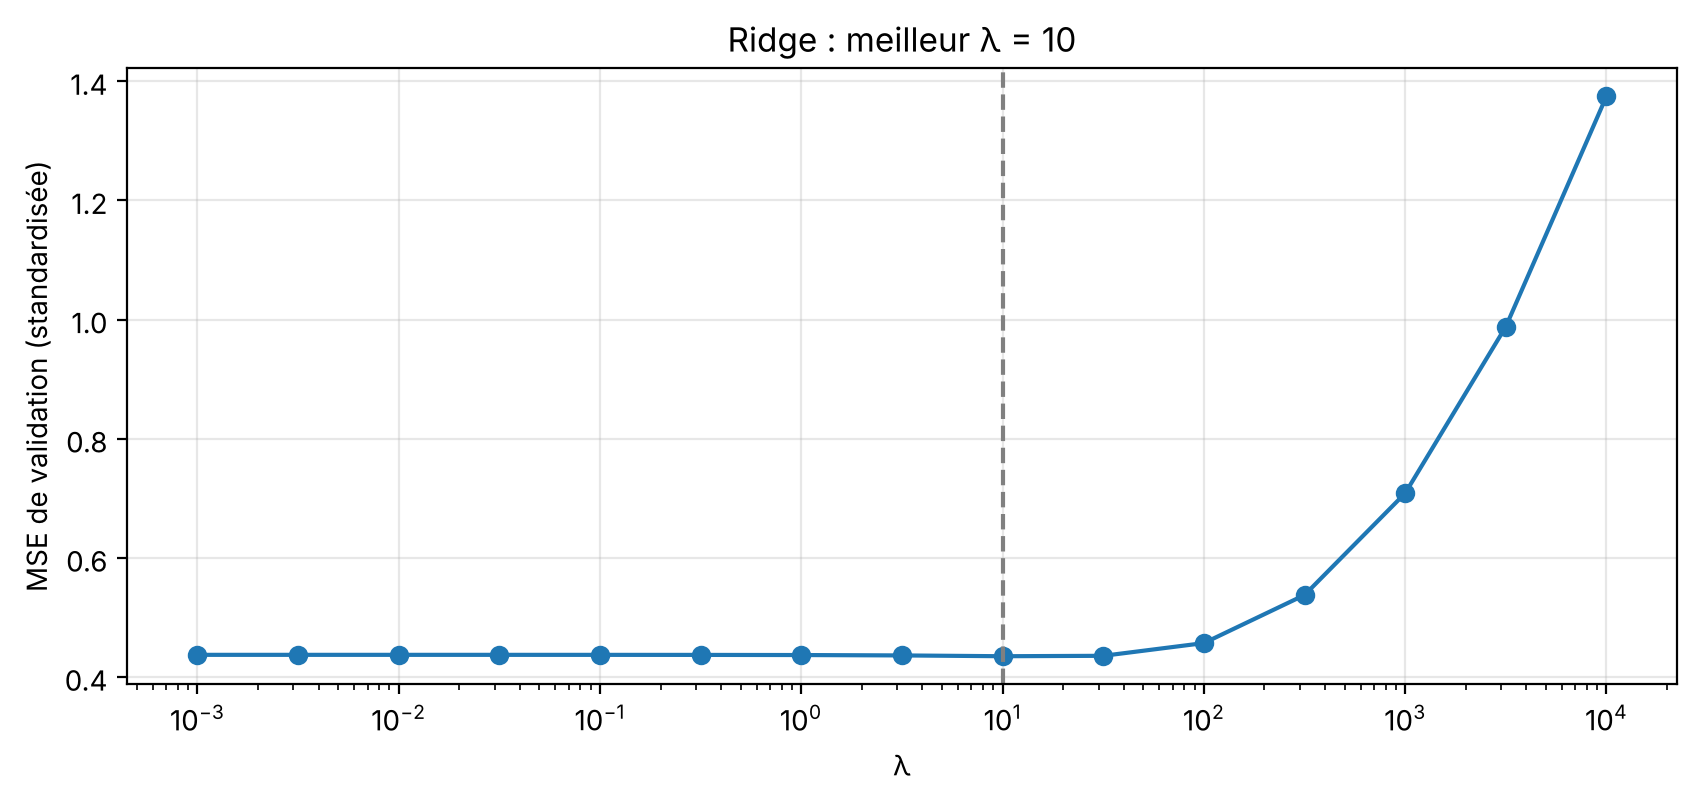

In [16]:
results = {}  # nom du modèle -> (erreur de validation, constructeur avec les meilleurs hyperparamètres)

results["Moyenne (référence)"] = (mse_standardized(Yva, MeanBaseline().fit(Xtr, Ytr).predict(Xva)),
                                  lambda: MeanBaseline())

lambdas = np.logspace(-3, 4, 15)
ridge_val = [mse_standardized(Yva, RidgeRegression(l).fit(Xtr, Ytr).predict(Xva)) for l in lambdas]
best_lam = lambdas[int(np.argmin(ridge_val))]

results["Moindres carrés"] = (mse_standardized(Yva, RidgeRegression(0.0).fit(Xtr, Ytr).predict(Xva)),
                              lambda: RidgeRegression(0.0))
results["Ridge"] = (min(ridge_val), lambda: RidgeRegression(best_lam))

plt.semilogx(lambdas, ridge_val, marker="o")
plt.axvline(best_lam, color="gray", ls="--")
plt.xlabel("λ"); plt.ylabel("MSE de validation (standardisée)")
plt.title(f"Ridge : meilleur λ = {best_lam:.3g}")
plt.show()

### 6.2 Ridge à noyau gaussien

Grille de 30 modèles en 23 s


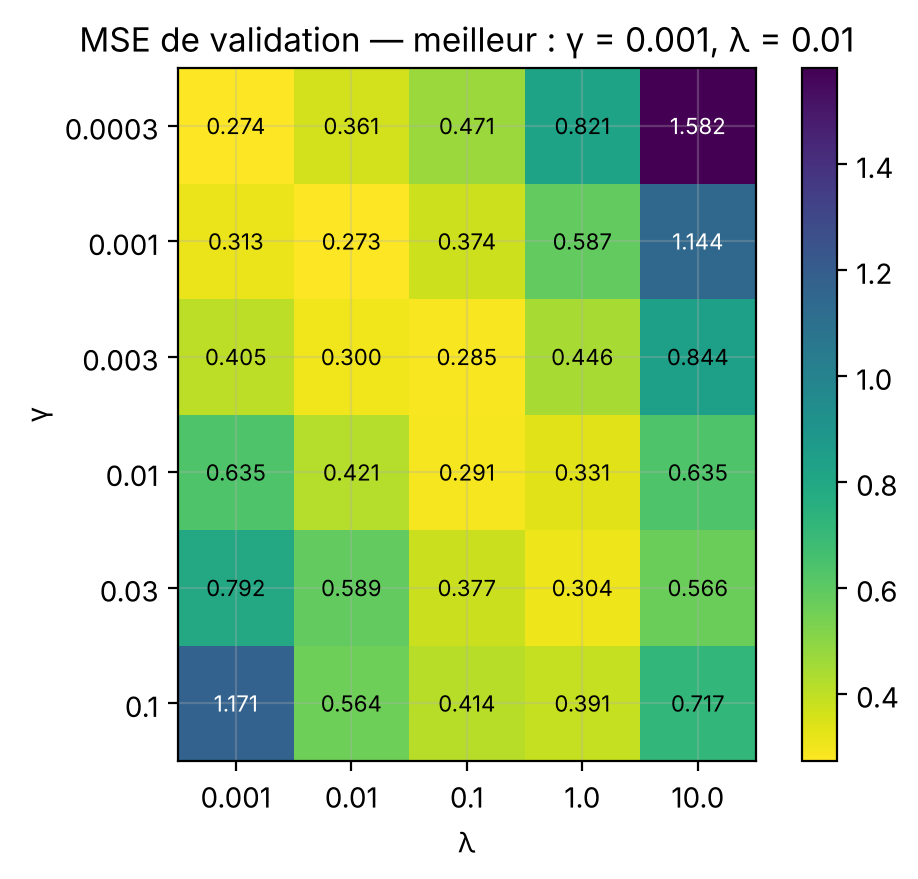

In [17]:
gammas = [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1]
lams = [1e-3, 1e-2, 1e-1, 1.0, 10.0]

t0 = time.time()
krr_val = np.array([[mse_standardized(Yva, KernelRidge(g, l).fit(Xtr, Ytr).predict(Xva)) for l in lams]
                    for g in gammas])
i, j = np.unravel_index(np.argmin(krr_val), krr_val.shape)
best_gamma, best_lam_krr = gammas[i], lams[j]
results["Ridge à noyau"] = (krr_val[i, j], lambda: KernelRidge(best_gamma, best_lam_krr))
print(f"Grille de {krr_val.size} modèles en {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(krr_val, cmap="viridis_r")
ax.set_xticks(range(len(lams)), lams); ax.set_yticks(range(len(gammas)), gammas)
ax.set(xlabel="λ", ylabel="γ", title=f"MSE de validation — meilleur : γ = {best_gamma}, λ = {best_lam_krr}")
for a in range(len(gammas)):
    for b in range(len(lams)):
        dark = krr_val[a, b] > krr_val.min() + 0.5 * (krr_val.max() - krr_val.min())
        ax.text(b, a, f"{krr_val[a, b]:.3f}", ha="center", va="center", fontsize=8,
                color="white" if dark else "black")
fig.colorbar(im)
plt.show()

Un $\gamma$ trop grand rend le noyau très local : le modèle mémorise le train et généralise mal (bas du tableau). Un $\gamma$ très petit rend le modèle presque linéaire et demande un $\lambda$ faible. Le meilleur compromis se trouve sur une « diagonale » où $\gamma$ et $\lambda$ diminuent ensemble. La standardisation est indispensable ici : sans elle, les distances $\|x - x'\|^2$ seraient dominées par les variables de grande échelle (réponses des capteurs, de l'ordre de 1000).

### 6.3 Réseau de neurones

{'hidden': (32,), 'weight_decay': 0.0}        -> MSE val = 0.3156  (meilleure époque : 91)


{'hidden': (32,), 'weight_decay': 0.001}      -> MSE val = 0.3086  (meilleure époque : 91)


{'hidden': (64, 64), 'weight_decay': 0.0}     -> MSE val = 0.3497  (meilleure époque : 13)


{'hidden': (64, 64), 'weight_decay': 0.001}   -> MSE val = 0.3240  (meilleure époque : 33)
Temps total : 2 s


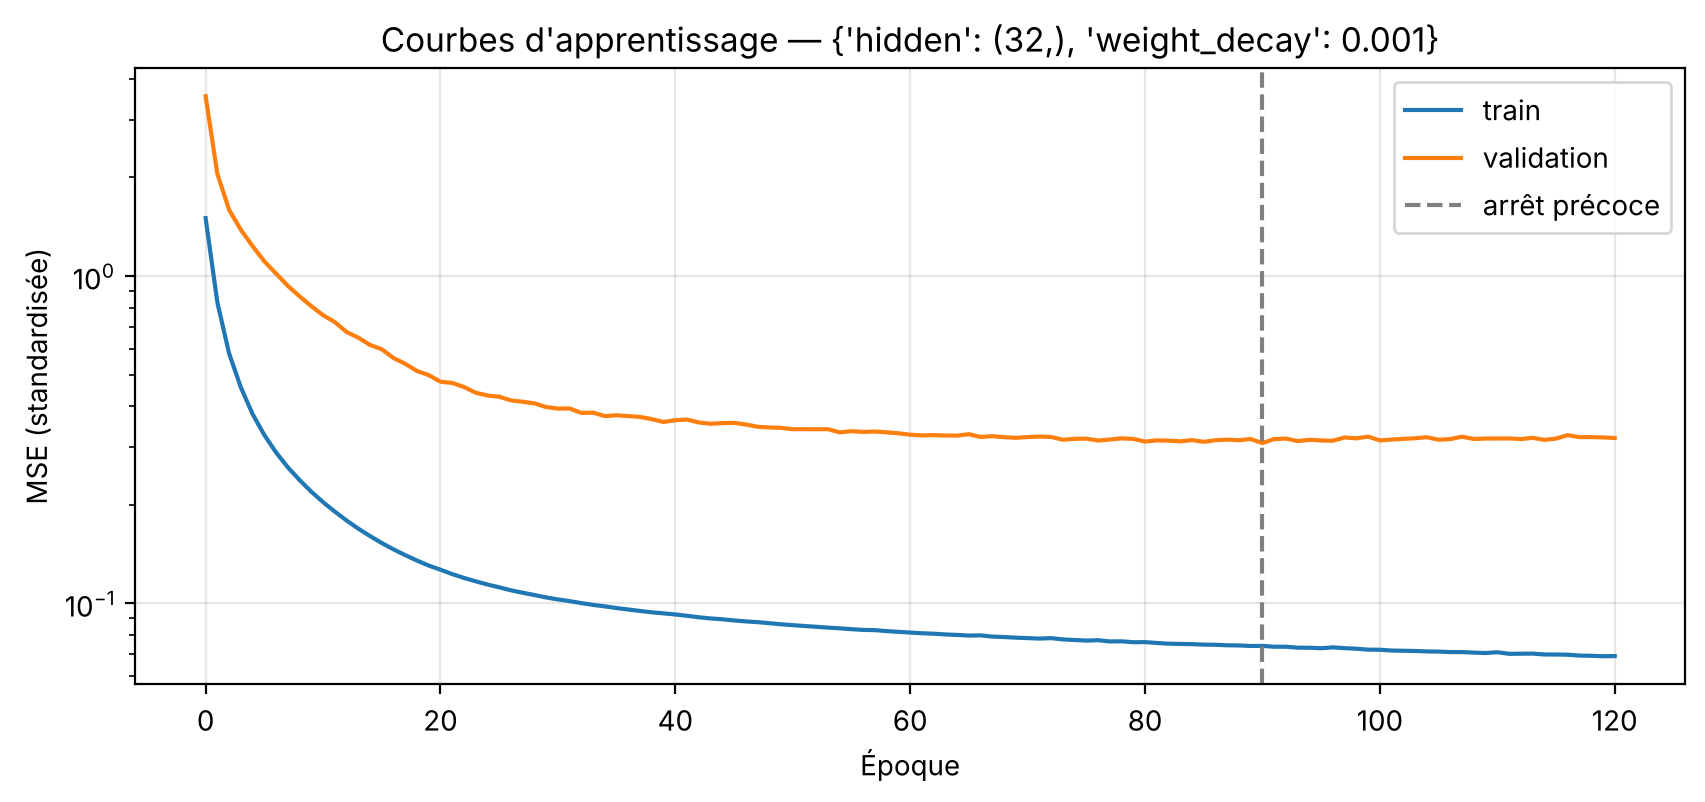

In [18]:
mlp_grid = [dict(hidden=h, weight_decay=wd) for h in [(32,), (64, 64)] for wd in [0.0, 1e-3]]

t0 = time.time()
mlp_runs = []
for cfg in mlp_grid:
    net = MLP(**cfg).fit(Xtr, Ytr, Xva, Yva)
    mlp_runs.append((min(net.history_["val"]), cfg, net))
    print(f"{str(cfg):45s} -> MSE val = {mlp_runs[-1][0]:.4f}  (meilleure époque : {net.best_epoch_})")
print(f"Temps total : {time.time() - t0:.0f} s")

best_mlp_val, best_cfg, best_net = min(mlp_runs, key=lambda r: r[0])
results["Réseau de neurones"] = (best_mlp_val,
                                 lambda: MLP(**best_cfg, epochs=best_net.best_epoch_, patience=np.inf))

plt.plot(best_net.history_["train"], label="train")
plt.plot(best_net.history_["val"], label="validation")
plt.axvline(best_net.best_epoch_ - 1, color="gray", ls="--", label="arrêt précoce")
plt.yscale("log"); plt.xlabel("Époque"); plt.ylabel("MSE (standardisée)")
plt.title(f"Courbes d'apprentissage — {best_cfg}")
plt.legend(); plt.show()

Pour l'évaluation finale, le réseau est ré-entraîné sur train + validation pendant le nombre d'époques choisi par l'arrêt précoce.

## 7. Évaluation finale sur le test

Chaque modèle est ré-entraîné avec ses meilleurs hyperparamètres sur **train + validation** (standardisation recalculée sur ces données), puis évalué **une seule fois** sur le test.

In [19]:
X_trval, Y_trval = X_all[:i_test], Y_all[:i_test]
xs, ys = Standardizer().fit(X_trval), Standardizer().fit(Y_trval)

rows, test_preds = [], {}
for name, (val_score, make_model) in results.items():
    model = make_model().fit(xs.transform(X_trval), ys.transform(Y_trval))
    Y_pred = ys.inverse_transform(model.predict(xs.transform(X_test)))
    test_preds[name] = Y_pred
    rows.append({"Modèle": name, "MSE val. (std.)": val_score,
                 **{f"RMSE {t}": v for t, v in zip(TARGETS, rmse_per_target(Y_test, Y_pred))},
                 **{f"R² {t}": v for t, v in zip(TARGETS, r2_per_target(Y_test, Y_pred))}})

summary = pd.DataFrame(rows).set_index("Modèle")
summary.style.format("{:.3f}").highlight_min(subset=summary.columns[:5], color="#c6efce") \
             .highlight_max(subset=summary.columns[5:], color="#c6efce")

,MSE val. (std.),RMSE CO(GT),RMSE C6H6(GT),RMSE NOx(GT),RMSE NO2(GT),R² CO(GT),R² C6H6(GT),R² NOx(GT),R² NO2(GT)
Modèle,,,,,,,,,
Moyenne (référence),2.549,1.329,6.965,201.968,65.150,-0.032,-0.221,-0.125,-0.596
Moindres carrés,0.437,0.490,1.425,76.587,36.057,0.860,0.949,0.838,0.511
Ridge,0.435,0.489,1.402,76.085,36.021,0.860,0.951,0.840,0.512
Ridge à noyau,0.273,0.435,0.376,62.401,33.631,0.889,0.996,0.893,0.575
Réseau de neurones,0.309,0.430,0.563,67.530,33.847,0.892,0.992,0.874,0.569


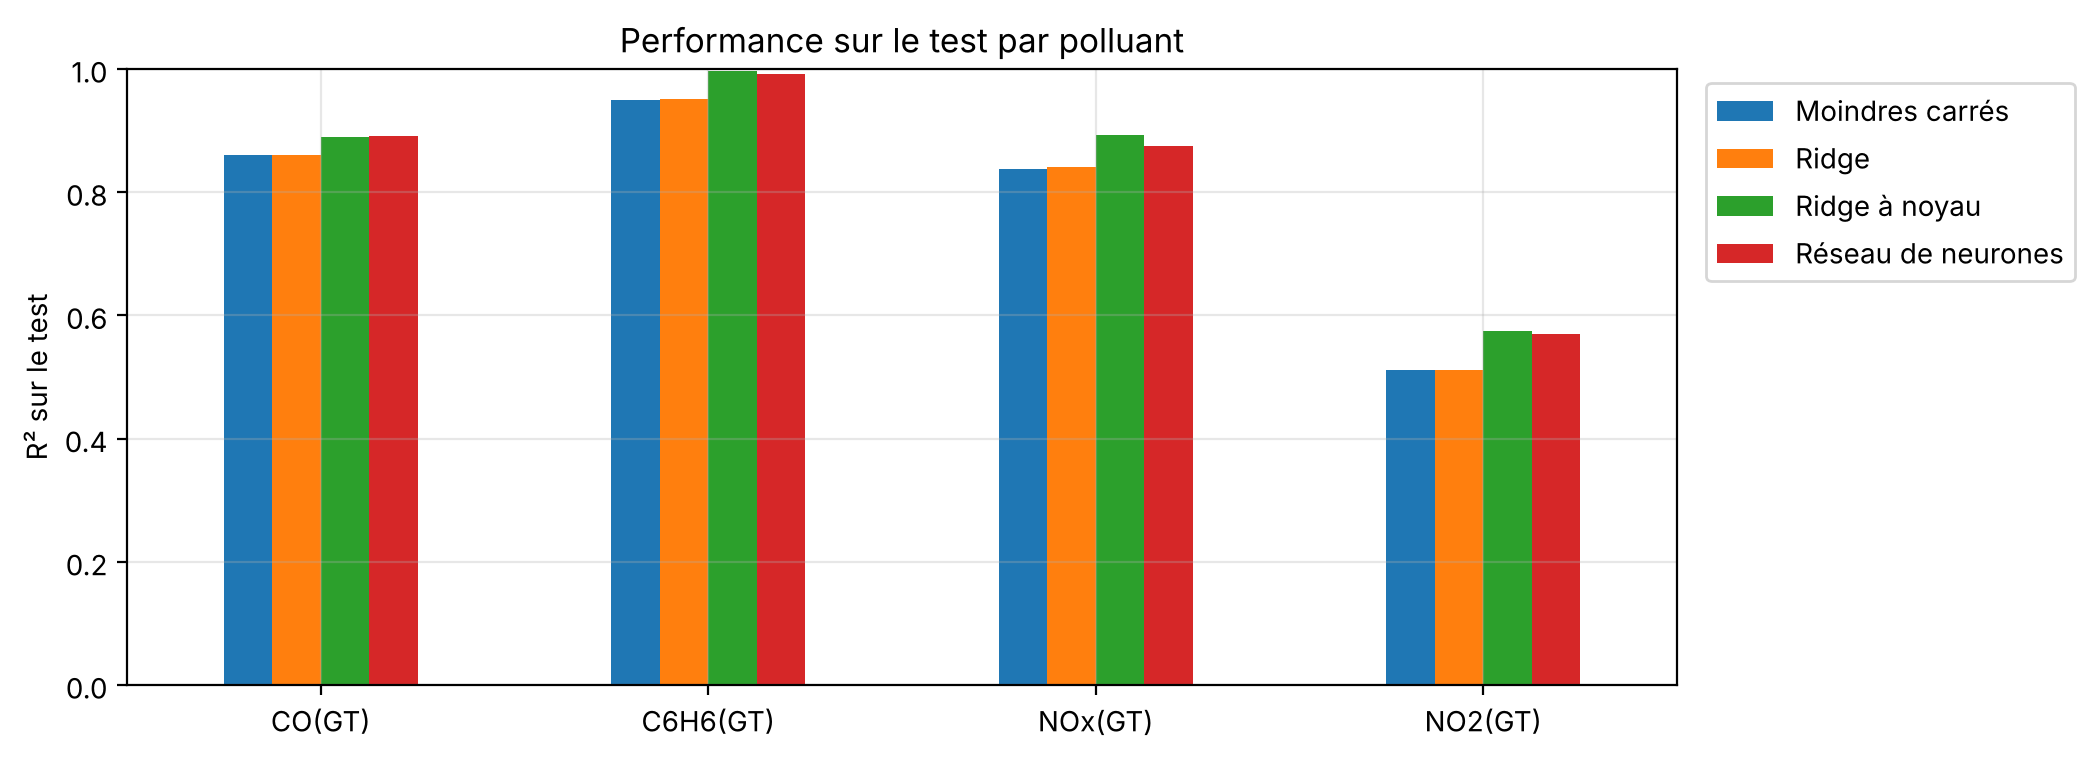

In [20]:
r2_cols = [f"R² {t}" for t in TARGETS]
ax = summary.drop(index="Moyenne (référence)")[r2_cols].T.plot.bar(figsize=(10, 4), rot=0)
ax.set_xticklabels(TARGETS); ax.set_ylabel("R² sur le test"); ax.set_ylim(0, 1)
ax.set_title("Performance sur le test par polluant")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1)); plt.show()

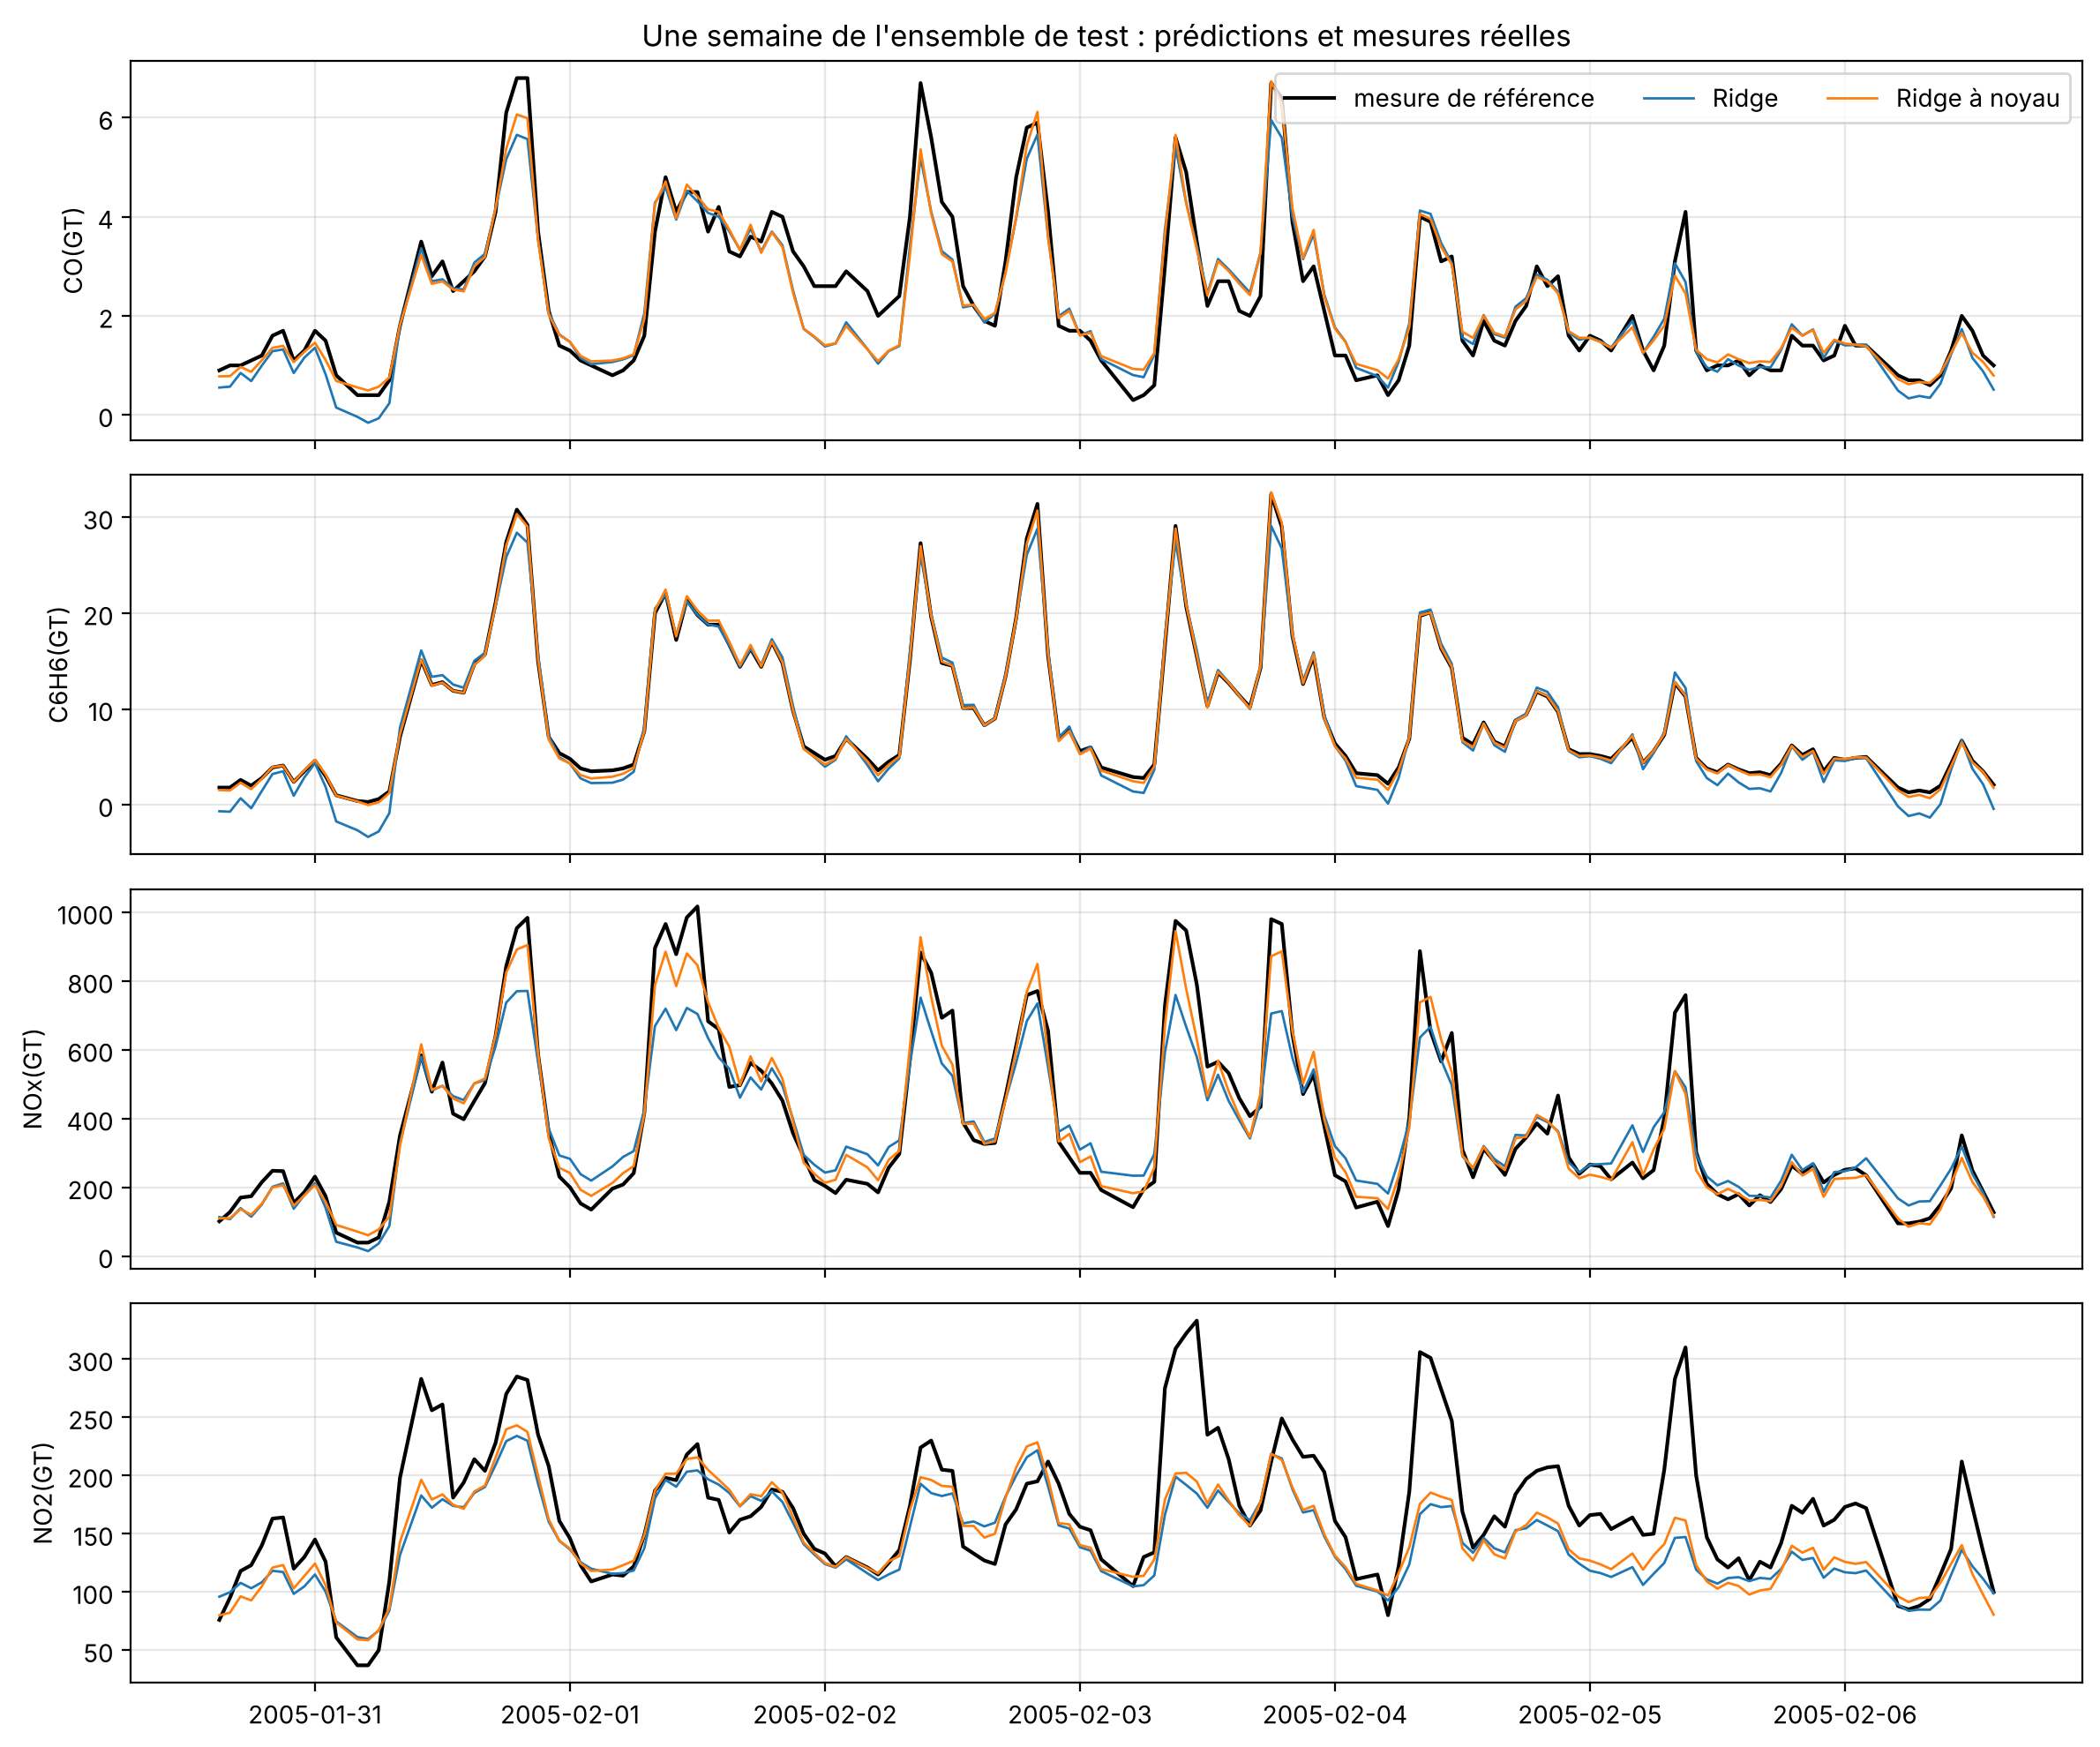

In [21]:
best_name = summary["MSE val. (std.)"].idxmin()
test_index = data.index[i_test:]
week = test_index < test_index[0] + pd.Timedelta(days=7)  # 7 jours calendaires

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
for k, (ax, target) in enumerate(zip(axes, TARGETS)):
    ax.plot(test_index[week], Y_test[week, k], color="black", lw=1.5, label="mesure de référence")
    ax.plot(test_index[week], test_preds["Ridge"][week, k], lw=1, label="Ridge")
    ax.plot(test_index[week], test_preds[best_name][week, k], lw=1, label=best_name)
    ax.set_ylabel(target)
axes[0].legend(ncol=3, loc="upper right")
axes[0].set_title("Une semaine de l'ensemble de test : prédictions et mesures réelles")
plt.tight_layout(); plt.show()

### Pourquoi un découpage chronologique ?

On refait l'évaluation de Ridge et de la Ridge à noyau avec un découpage **aléatoire** (même taille de test). L'écart montre à quel point un découpage aléatoire serait trop optimiste sur des séries temporelles : des heures voisines, presque identiques, se retrouvent de part et d'autre de la coupure.

In [22]:
perm = np.random.default_rng(SEED).permutation(n)
tr, te = perm[:i_test], perm[i_test:]
xs_r, ys_r = Standardizer().fit(X_all[tr]), Standardizer().fit(Y_all[tr])

comparison = {}
for name in ["Ridge", "Ridge à noyau"]:
    model = results[name][1]().fit(xs_r.transform(X_all[tr]), ys_r.transform(Y_all[tr]))
    pred = ys_r.inverse_transform(model.predict(xs_r.transform(X_all[te])))
    comparison[name] = {"R² moyen, découpage chronologique": summary.loc[name, r2_cols].mean(),
                        "R² moyen, découpage aléatoire": r2_per_target(Y_all[te], pred).mean()}
pd.DataFrame(comparison).T.round(3)

,"R² moyen, découpage chronologique","R² moyen, découpage aléatoire"
Ridge,0.791,0.883
Ridge à noyau,0.838,0.923


## 8. Conclusion

Les chiffres ci-dessous proviennent du tableau de la section 7 (ensemble de test : 30/01/2005 – 04/04/2005).

- **Tous les modèles battent nettement la référence naïve.** Celle-ci a même un $R^2$ négatif : la moyenne du train n'est pas un bon prédicteur de la période de test, signe d'un décalage de distribution entre les deux périodes.
- **Moindres carrés et Ridge donnent presque les mêmes résultats** ($R^2$ ≈ 0,86 pour CO, 0,95 pour le benzène, 0,84 pour NOx, 0,51 pour NO2). Avec environ 4 000 observations pour 11 variables standardisées, le problème est bien posé et la régularisation n'apporte que peu.
- **La Ridge à noyau gaussien est la meilleure méthode** (meilleure erreur de validation, et $R^2$ ≈ 0,89 / 0,996 / 0,89 / 0,58 sur le test). Les relations entre réponses des capteurs et concentrations sont non linéaires, ce que le noyau capture.
- **Le réseau de neurones fait presque aussi bien** (légèrement meilleur sur CO, moins bon sur le benzène et NOx). Avec si peu de variables, un petit réseau (une couche cachée de 32 neurones) suffit ; les réseaux plus profonds sur-apprennent plus vite.
- **Le benzène est prédit presque parfaitement** ($R^2$ ≈ 0,996). Il est corrélé à 0,98 avec le capteur `PT08.S2(NMHC)` et ses valeurs manquantes coïncident exactement avec celles des capteurs. Cela suggère que, dans ce jeu de données, sa mesure est très directement liée à ce capteur : ce résultat est à interpréter avec prudence.
- **NO2 est le polluant le plus difficile** ($R^2$ ≈ 0,58 au mieux). Son niveau moyen augmente fortement en hiver (environ 94 µg/m³ en juin contre 160 en février) : le modèle, appris de mars à novembre, doit extrapoler vers des niveaux qu'il a peu vus.
- **Le découpage aléatoire surestime les performances** : le $R^2$ moyen de la Ridge à noyau passe de 0,84 (chronologique) à 0,92 (aléatoire). Sur des séries temporelles, seul un découpage chronologique mesure la vraie capacité à prédire le futur.

### Limites et pistes
- **Dérive des capteurs :** les capteurs à oxydes métalliques dérivent dans le temps et le test (fin de l'enregistrement, en hiver) ne suit pas exactement la distribution du train. Un ré-étalonnage périodique ou un entraînement sur fenêtre glissante serait plus réaliste.
- **Valeurs manquantes :** on a supprimé les heures incomplètes ; une imputation permettrait d'utiliser plus de données.
- **Dépendance temporelle :** les modèles traitent chaque heure indépendamment. Ajouter des valeurs passées des capteurs (variables retardées) ou utiliser un modèle séquentiel pourrait améliorer les prédictions.
- **Coût de la méthode à noyau :** la résolution coûte $O(n^3)$ ; pour plus de données, des approximations (Nyström, features aléatoires de Fourier) seraient nécessaires.